In [20]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root
PROJECT_ROOT = Path.cwd().parent

# Add project root to Python path
sys.path.insert(0, str(PROJECT_ROOT))

from src.fraud_detection.data import load_data

print("EDA environment ready!")

EDA environment ready!


In [21]:
df = load_data()

print(f"Dataset shape: {df.shape}")
print(f"Number of transactions: {len(df):,}")

Dataset shape: (284807, 31)
Number of transactions: 284,807


In [22]:
from src.fraud_detection.config import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figures will be saved to: {FIGURES_DIR}")

Figures will be saved to: C:\Data Science Projects\Credit Card Fraud Detection\reports\figures


In [23]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [26]:
class_counts = df["Class"].value_counts()

print("Transaction counts:")
print(class_counts)

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64


In [27]:
class_percentage = df["Class"].value_counts(normalize=True) * 100

print("Transaction percentages:")
print(class_percentage)

Transaction percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


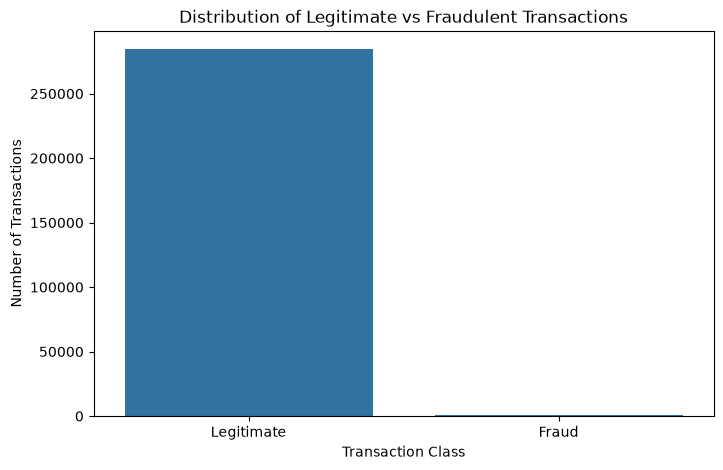

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.title("Distribution of Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])

plt.show()

In [29]:
fraud_percentage = (df["Class"].sum() / len(df)) * 100

print(f"Fraud transaction percentage: {fraud_percentage:.4f}%")

Fraud transaction percentage: 0.1727%


In [30]:
amount_summary = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

amount_summary

,count,mean,median,min,max
Class,,,,,
0,284315,88.291022,22.00,0.0,25691.16
1,492,122.211321,9.25,0.0,2125.87


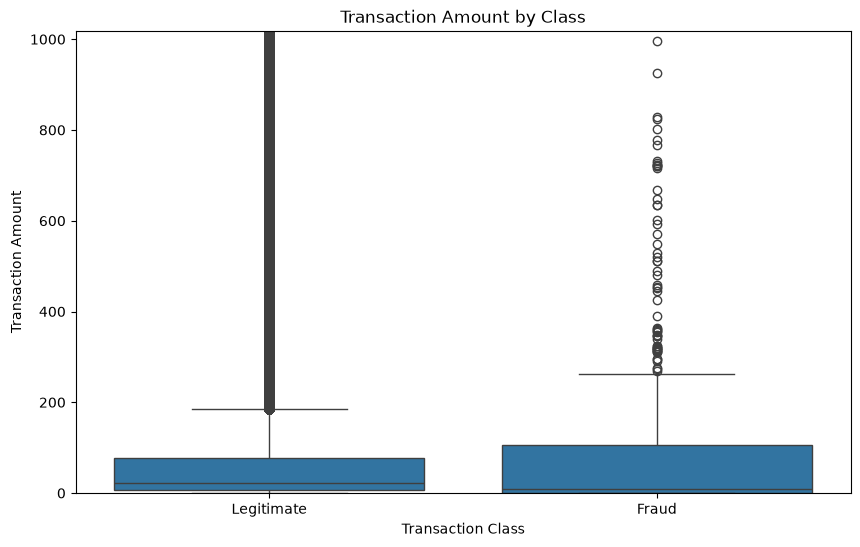

In [31]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate", "Fraud"])

plt.ylim(0, df["Amount"].quantile(0.99))

plt.show()

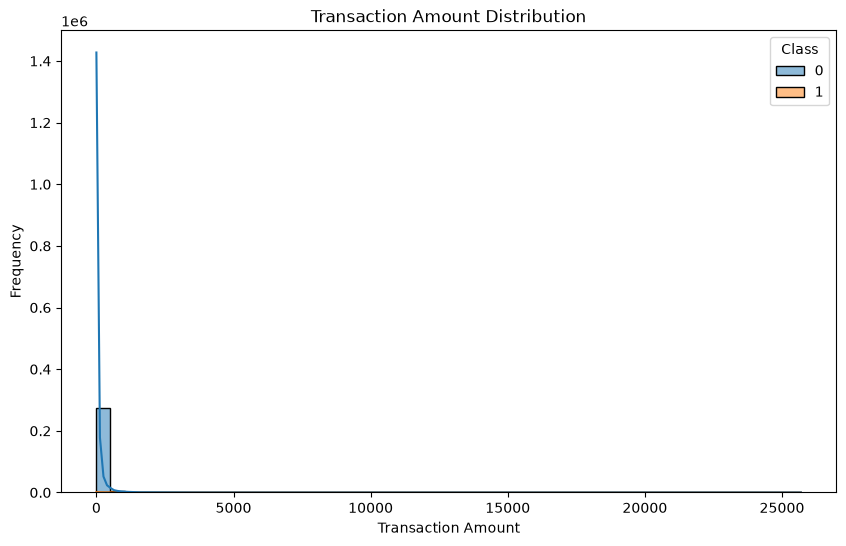

In [32]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    kde=True
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

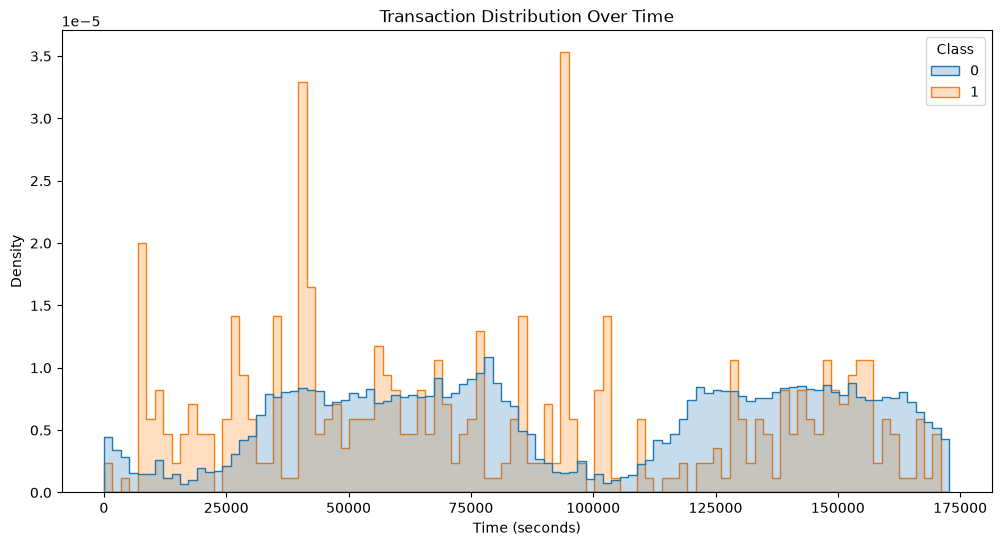

In [33]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Distribution Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Density")

plt.show()

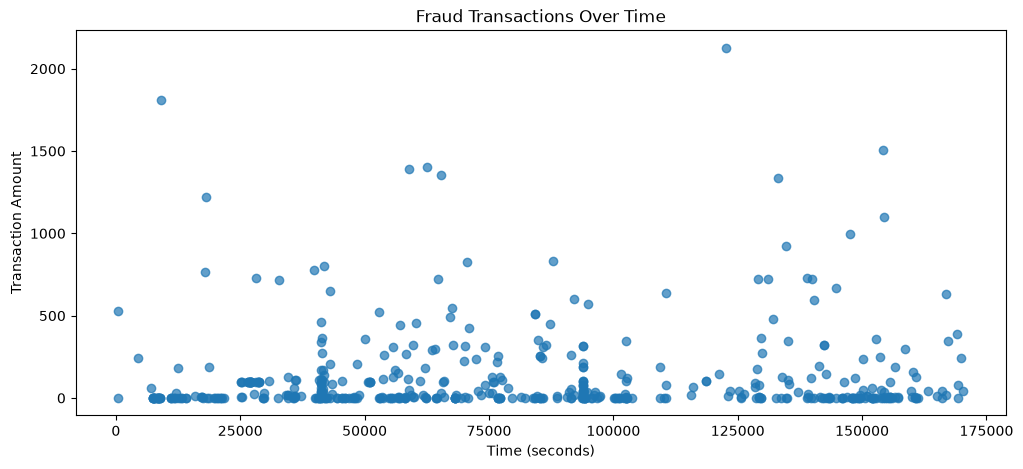

In [34]:
fraud_df = df[df["Class"] == 1].copy()

plt.figure(figsize=(12, 5))

plt.scatter(
    fraud_df["Time"],
    fraud_df["Amount"],
    alpha=0.7
)

plt.title("Fraud Transactions Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Transaction Amount")

plt.show()

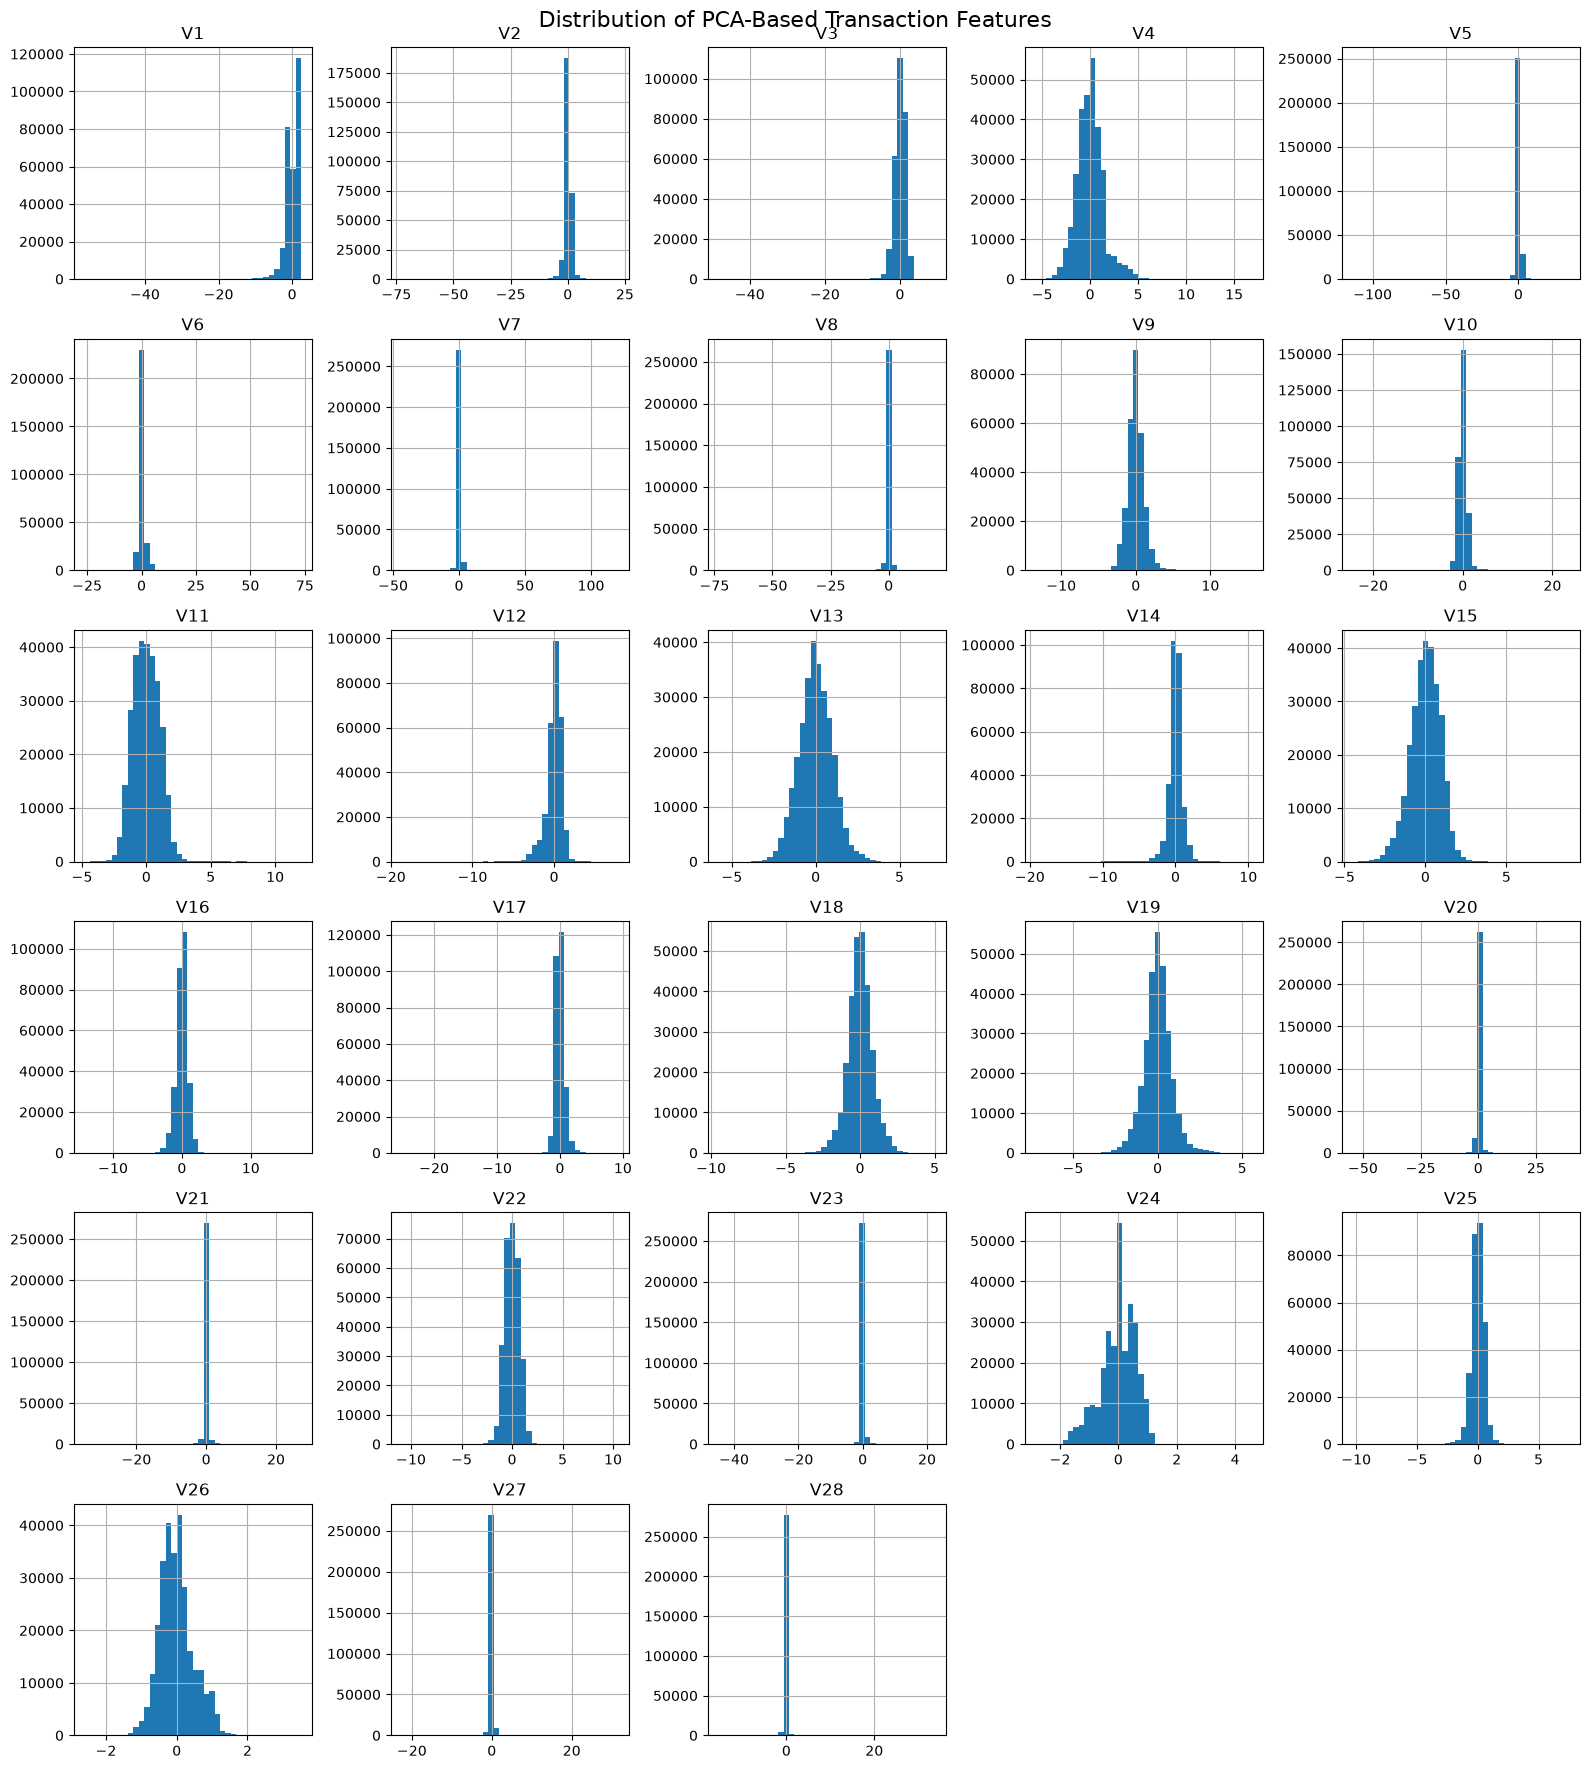

In [35]:
v_features = [f"V{i}" for i in range(1, 29)]

df[v_features].hist(
    figsize=(16, 18),
    bins=40
)

plt.suptitle("Distribution of PCA-Based Transaction Features", fontsize=16)

plt.tight_layout()
plt.show()

In [36]:
correlation_with_class = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values()
)

correlation_with_class

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V6       -0.043643
Time     -0.012323
V24      -0.007221
V13      -0.004570
V15      -0.004223
V23      -0.002685
V22       0.000805
V25       0.003308
V26       0.004455
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Name: Class, dtype: float64

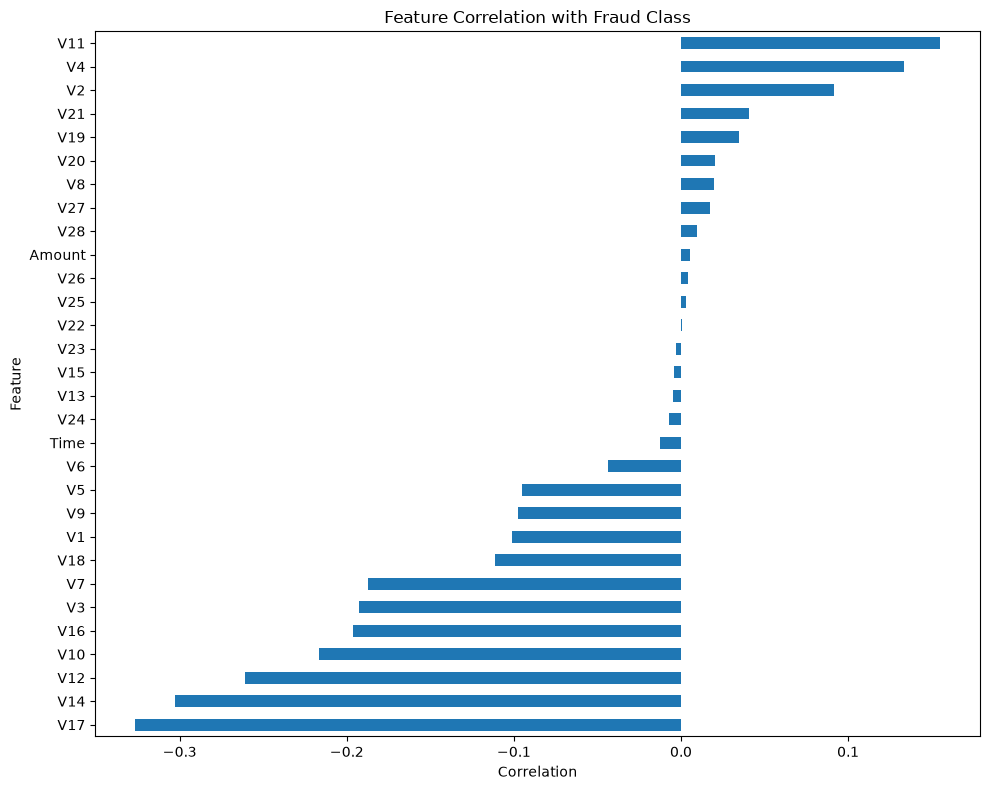

In [37]:
plt.figure(figsize=(10, 8))

correlation_with_class.plot(kind="barh")

plt.title("Feature Correlation with Fraud Class")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

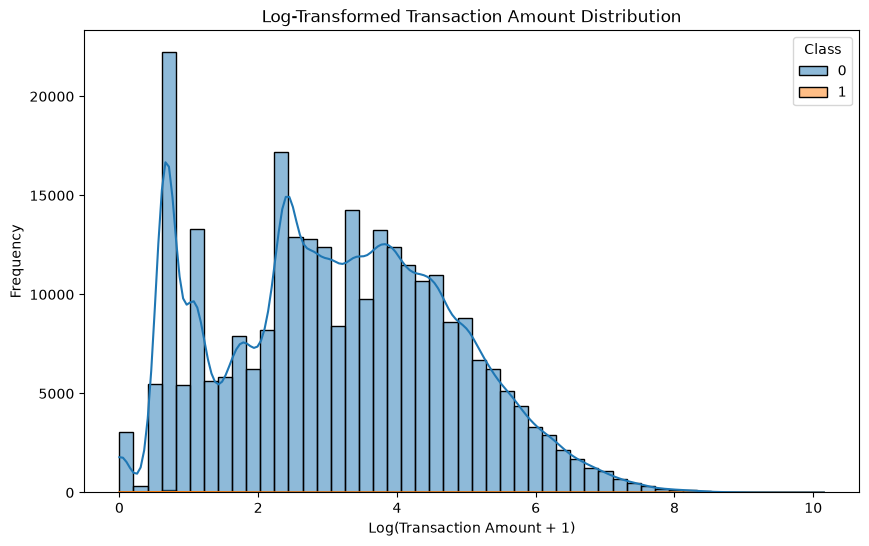

In [38]:
df["Amount_log"] = np.log1p(df["Amount"])

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Amount_log",
    hue="Class",
    bins=50,
    kde=True,
    common_norm=False
)

plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("Log(Transaction Amount + 1)")
plt.ylabel("Frequency")

plt.show()

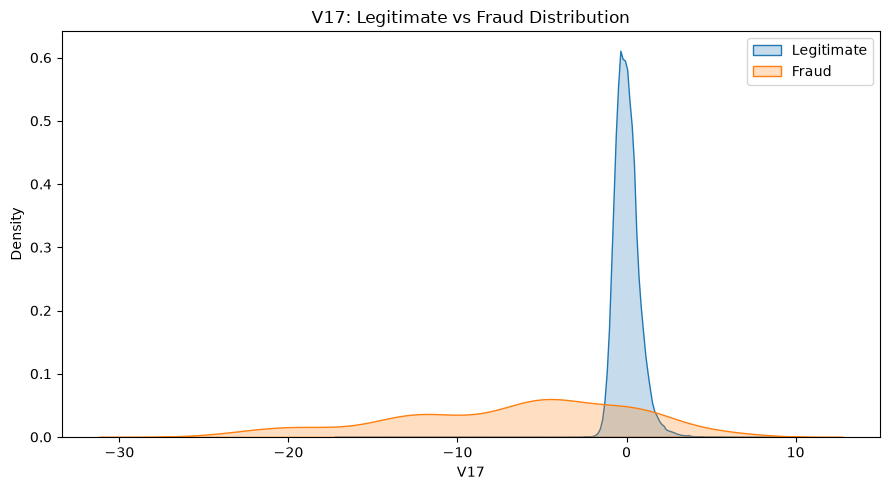

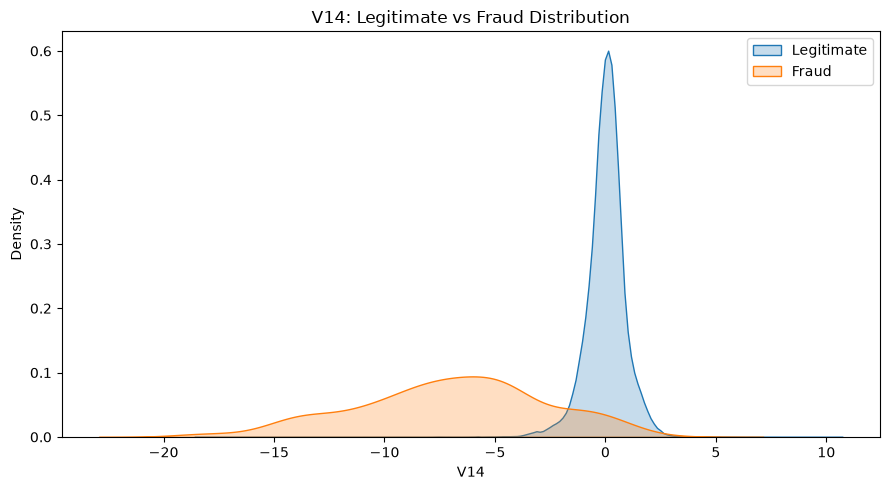

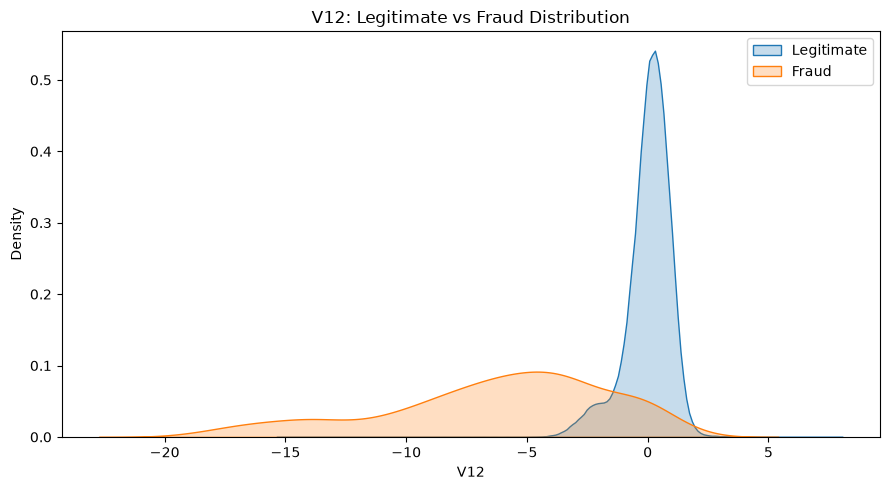

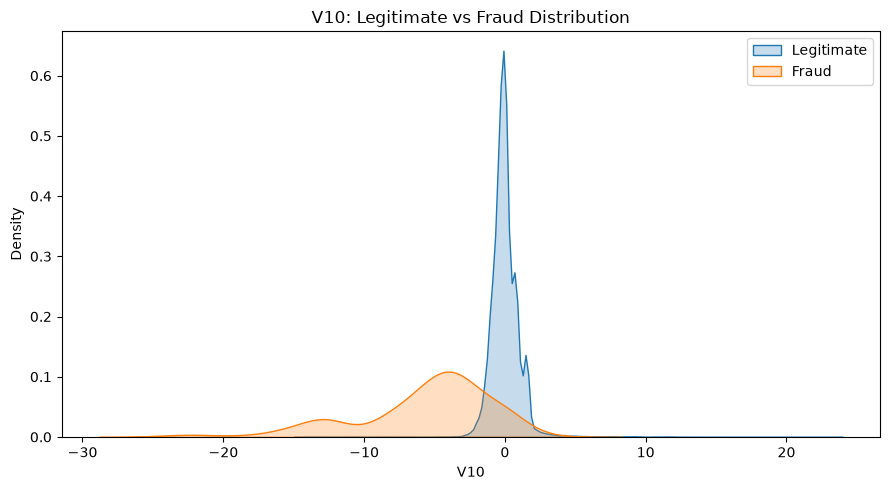

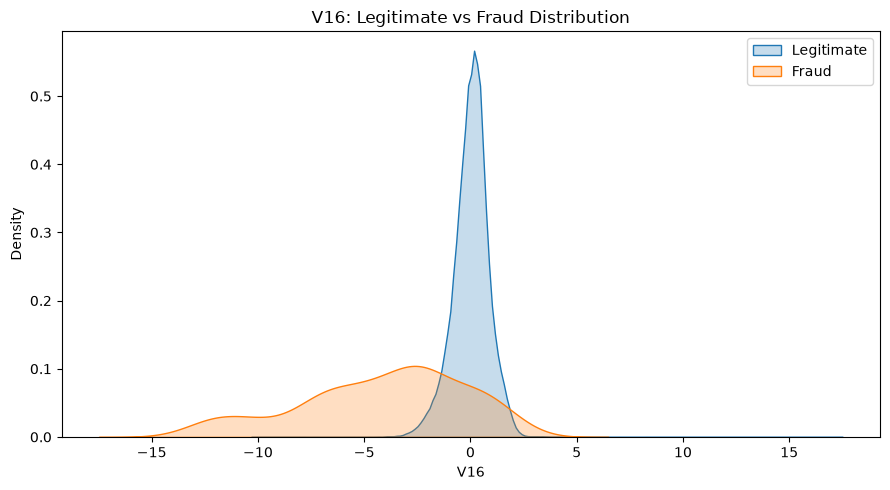

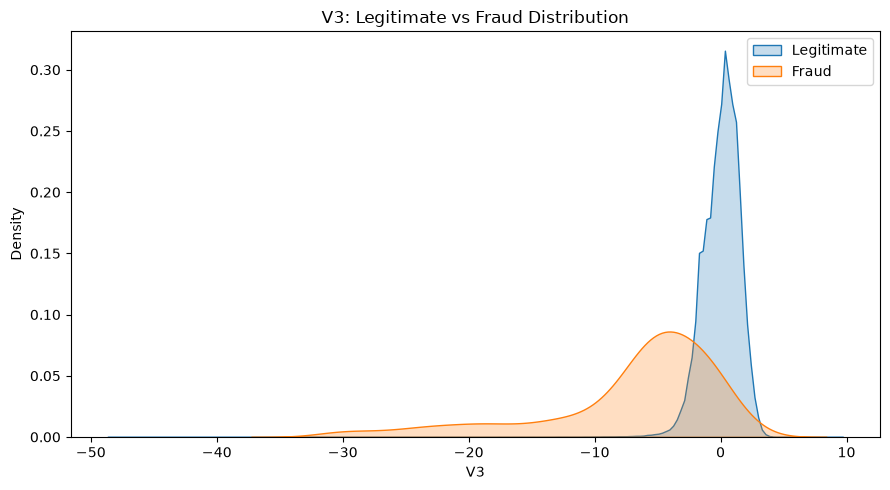

In [43]:
top_features = ["V17", "V14", "V12", "V10", "V16", "V3"]

for feature in top_features:
    plt.figure(figsize=(9, 5))

    sns.kdeplot(
        data=df[df["Class"] == 0],
        x=feature,
        label="Legitimate",
        fill=True
    )

    sns.kdeplot(
        data=df[df["Class"] == 1],
        x=feature,
        label="Fraud",
        fill=True
    )

    plt.title(f"{feature}: Legitimate vs Fraud Distribution")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()

    plt.tight_layout()
    plt.show()